# Task 2: MySQL and MongoDB Database Design
## Beijing Multi-Site Air Quality Dataset

**Member 2** | Builds on Task 1 (preprocessing, EDA, and ML model)

---

### Overview

This notebook designs and implements two databases for the Beijing Air Quality time-series dataset:

| Component | Technology | Contents |
|-----------|-----------|----------|
| Relational DB | MySQL 8.4, hosted on Aiven | 3 normalized tables, 420 768 hourly rows |
| Document DB | MongoDB, hosted on MongoDB Atlas | 1 collection, 420 768 documents |

All schema scripts and queries run against the **real hosted databases** that the Task 3 API also uses. Both were loaded once from the 12 station CSVs by `database/load_data.py`; this notebook connects to them, verifies the data, and runs the queries.

> **Credentials** are read from the project's `.env` file (`SQL_DATABASE_URL`, `SQL_SSL`, `MONGO_URI`), never written in the notebook. Copy `.env.example` to `.env` and fill in the connection strings before running.

---
## Section 1: Load Dataset

In [1]:
import os, glob, json, math, time, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from datetime import datetime
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from pymongo import MongoClient

warnings.filterwarnings('ignore')

# Connection strings come from .env (git-ignored), never from this notebook.
load_dotenv()
for var in ('SQL_DATABASE_URL', 'MONGO_URI'):
    if not os.getenv(var):
        raise RuntimeError(f'{var} is not set. Copy .env.example to .env and fill it in.')

print('All packages ready.')

All packages ready.


In [2]:
# ── Locate the 12 station CSV files ──────────────────────────────────────────
# Locally: unzip the Kaggle archive into data/raw/. On Kaggle: /kaggle/input/.
csv_files = (glob.glob('data/raw/**/*.csv', recursive=True)          # run from the repo root
             or glob.glob('../data/raw/**/*.csv', recursive=True)    # run from notebooks/
             or glob.glob('/kaggle/input/**/*.csv', recursive=True))

if not csv_files:
    raise FileNotFoundError(
        'No CSV files found under data/raw/ or /kaggle/input/.\n'
        'Add the Beijing Multi-Site Air Quality dataset to this notebook.'
    )

print(f'Found {len(csv_files)} CSV file(s):')
for f in sorted(csv_files):
    print(f'  {f}')

# Combine all station files into one DataFrame
df_raw = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)

# Build a proper timestamp from the four date components
df_raw['timestamp'] = pd.to_datetime(df_raw[['year', 'month', 'day', 'hour']])

print(f'\nDataset loaded: {len(df_raw):,} rows × {len(df_raw.columns)} columns')
print(f'Time range : {df_raw["timestamp"].min()}  →  {df_raw["timestamp"].max()}')
print(f'Stations   : {sorted(df_raw["station"].unique().tolist())}')

Found 12 CSV file(s):
  ../data/raw/PRSA_Data_Aotizhongxin_20130301-20170228.csv
  ../data/raw/PRSA_Data_Changping_20130301-20170228.csv
  ../data/raw/PRSA_Data_Dingling_20130301-20170228.csv
  ../data/raw/PRSA_Data_Dongsi_20130301-20170228.csv
  ../data/raw/PRSA_Data_Guanyuan_20130301-20170228.csv
  ../data/raw/PRSA_Data_Gucheng_20130301-20170228.csv
  ../data/raw/PRSA_Data_Huairou_20130301-20170228.csv
  ../data/raw/PRSA_Data_Nongzhanguan_20130301-20170228.csv
  ../data/raw/PRSA_Data_Shunyi_20130301-20170228.csv
  ../data/raw/PRSA_Data_Tiantan_20130301-20170228.csv
  ../data/raw/PRSA_Data_Wanliu_20130301-20170228.csv
  ../data/raw/PRSA_Data_Wanshouxigong_20130301-20170228.csv



Dataset loaded: 420,768 rows × 19 columns
Time range : 2013-03-01 00:00:00  →  2017-02-28 23:00:00
Stations   : ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']


In [3]:
print('Columns:', df_raw.columns.tolist())
print()
display(df_raw.head(3))
print(f'\nShape: {df_raw.shape}')
print('\nMissing values per column:')
display(df_raw.isnull().sum().rename('missing').to_frame())

Columns: ['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station', 'timestamp']



,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,timestamp
0,1,2013,3,1,0,6.0,18.0,5.0,NaN,800.0,88.0,0.1,1021.1,-18.6,0.0,NW,4.4,Gucheng,2013-03-01 00:00:00
1,2,2013,3,1,1,6.0,15.0,5.0,NaN,800.0,88.0,-0.3,1021.5,-19.0,0.0,NW,4.0,Gucheng,2013-03-01 01:00:00
2,3,2013,3,1,2,5.0,18.0,NaN,NaN,700.0,52.0,-0.7,1021.5,-19.8,0.0,WNW,4.6,Gucheng,2013-03-01 02:00:00



Shape: (420768, 19)

Missing values per column:


,missing
No,0
year,0
month,0
day,0
hour,0
PM2.5,8739
PM10,6449
SO2,9021
NO2,12116
CO,20701


---
## Section 2: Relational Database Schema Design

### Table Descriptions

| Table | Role | Row count |
|-------|------|-----------|
| `stations` | Master record for each monitoring station | 12 |
| `readings` | Hourly measurement fact table — all pollutant and weather values | 420 768 |
| `pollutant_reference` | WHO guideline lookup per pollutant | 6 |

### Design Rationale
- **stations** normalises the station name out of the 420 768-row fact table (12 rows instead of 420 768 repeated strings).
- **readings** holds the time-series core. A composite `UNIQUE (station_id, timestamp)` constraint guarantees no duplicate hourly records per station. Two indexes (`timestamp`, `station_id + timestamp`) support the date-range and latest-record queries that Task 3 will expose as API endpoints.
- **pollutant_reference** stores WHO 2021 air-quality guidelines per pollutant, enabling threshold queries without hardcoding values in application code. It is a lookup / reference table — no FK is added to `readings` because all six pollutants are always measured together in the same row.

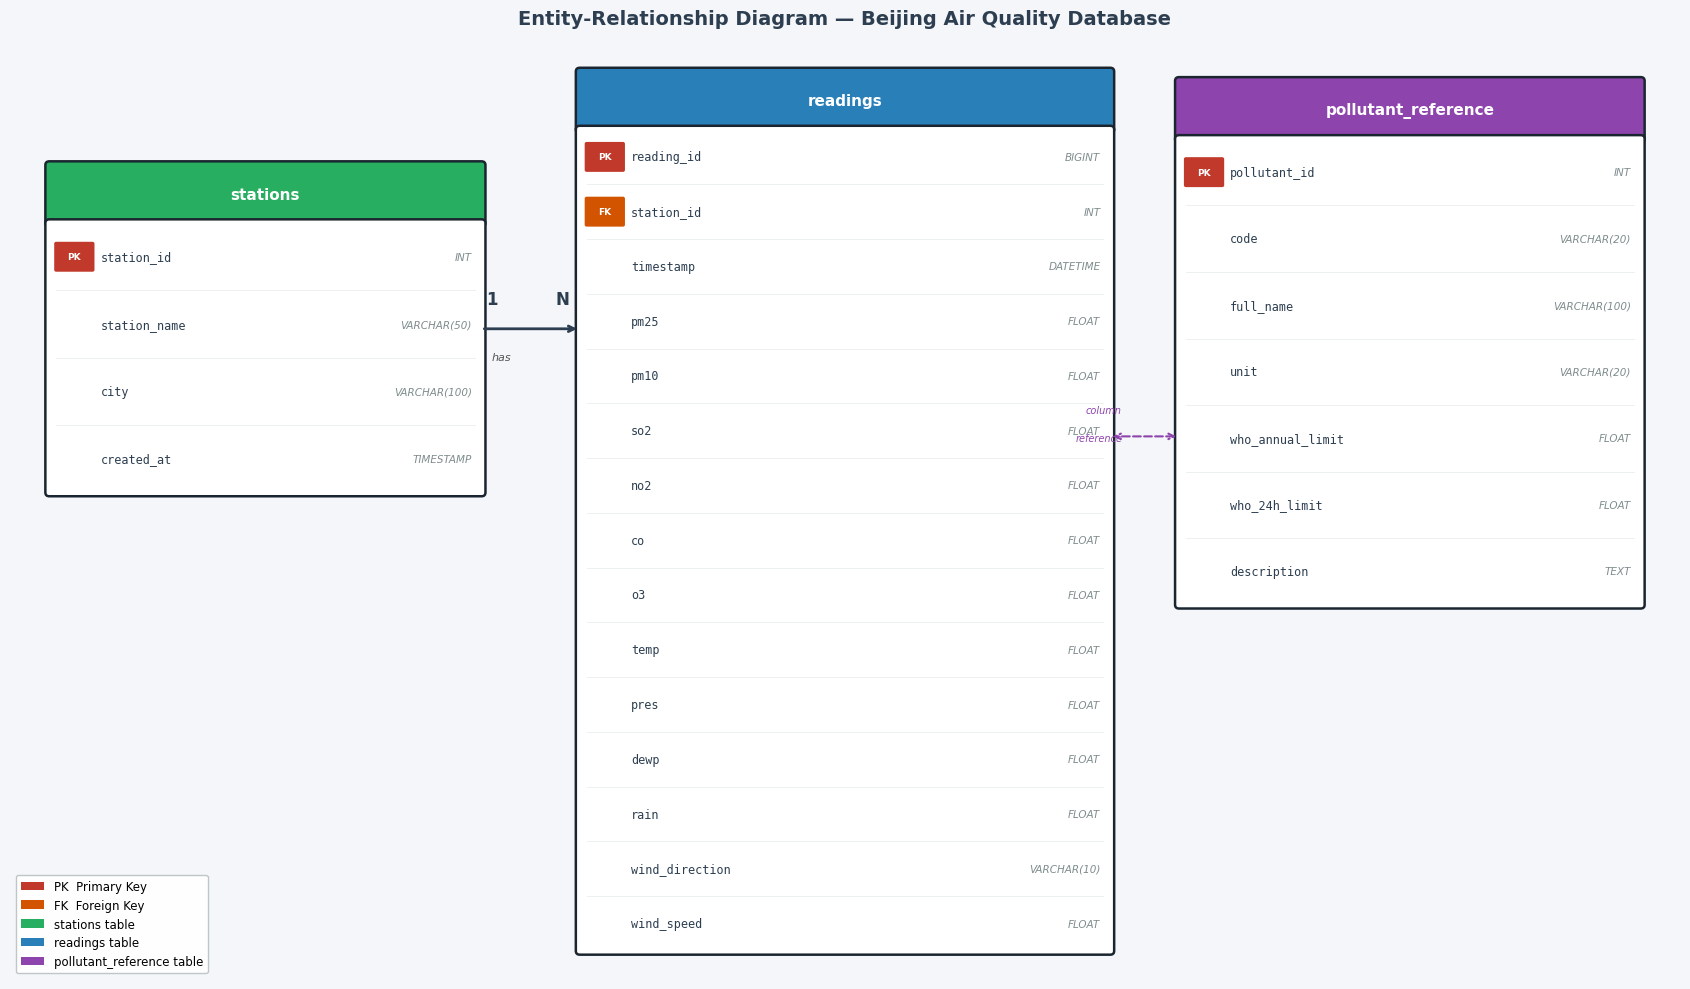

ERD saved → erd_beijing_air_quality.png


In [4]:
# ── Entity-Relationship Diagram ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(17, 10))
ax.set_xlim(0, 17)
ax.set_ylim(0, 10)
ax.axis('off')
ax.set_facecolor('#f4f6f9')
fig.patch.set_facecolor('#f4f6f9')
ax.set_title('Entity-Relationship Diagram — Beijing Air Quality Database',
             fontsize=14, fontweight='bold', pad=14, color='#2c3e50')

COLOR = {'pk': '#c0392b', 'fk': '#d35400', 'none': '#7f8c8d',
          'stations': '#27ae60', 'readings': '#2980b9', 'ref': '#8e44ad'}

def draw_table(ax, x, y, w, h, title, rows, hdr_color):
    """Draw one entity box with a coloured header and attribute rows."""
    row_h = (h - 0.62) / max(len(rows), 1)

    # header
    hdr = FancyBboxPatch((x, y + h - 0.62), w, 0.62,
                         boxstyle='round,pad=0.04',
                         facecolor=hdr_color, edgecolor='#1a252f', linewidth=1.8)
    ax.add_patch(hdr)
    ax.text(x + w / 2, y + h - 0.31, title,
            ha='center', va='center', fontsize=11, fontweight='bold', color='white')

    # body
    body = FancyBboxPatch((x, y), w, h - 0.62,
                          boxstyle='round,pad=0.04',
                          facecolor='white', edgecolor='#1a252f', linewidth=1.8)
    ax.add_patch(body)

    for i, (ktype, col, dtype) in enumerate(rows):
        ry = y + h - 0.62 - (i + 0.5) * row_h

        if ktype == 'PK':
            badge_color, symbol = COLOR['pk'], 'PK'
        elif ktype == 'FK':
            badge_color, symbol = COLOR['fk'], 'FK'
        else:
            badge_color, symbol = COLOR['none'], ''

        if symbol:
            badge = FancyBboxPatch((x + 0.07, ry - 0.14), 0.37, 0.28,
                                   boxstyle='round,pad=0.02',
                                   facecolor=badge_color, edgecolor='none')
            ax.add_patch(badge)
            ax.text(x + 0.255, ry, symbol,
                    ha='center', va='center', fontsize=6.5, fontweight='bold', color='white')

        ax.text(x + 0.52, ry, col,
                ha='left', va='center', fontsize=8.5,
                color='#2c3e50', fontfamily='monospace')
        ax.text(x + w - 0.1, ry, dtype,
                ha='right', va='center', fontsize=7.5, color='#7f8c8d', style='italic')

        if i < len(rows) - 1:
            sep_y = ry - row_h / 2
            ax.plot([x + 0.07, x + w - 0.07], [sep_y, sep_y],
                    color='#ecf0f1', linewidth=0.7)

# ── stations (left) ──────────────────────────────────────────────────────────
stations_rows = [
    ('PK', 'station_id',   'INT'),
    ('',   'station_name', 'VARCHAR(50)'),
    ('',   'city',         'VARCHAR(100)'),
    ('',   'created_at',   'TIMESTAMP'),
]
draw_table(ax, 0.4, 5.2, 4.4, 3.5, 'stations', stations_rows, COLOR['stations'])

# ── readings (centre) ────────────────────────────────────────────────────────
readings_rows = [
    ('PK', 'reading_id',     'BIGINT'),
    ('FK', 'station_id',     'INT'),
    ('',   'timestamp',      'DATETIME'),
    ('',   'pm25',           'FLOAT'),
    ('',   'pm10',           'FLOAT'),
    ('',   'so2',            'FLOAT'),
    ('',   'no2',            'FLOAT'),
    ('',   'co',             'FLOAT'),
    ('',   'o3',             'FLOAT'),
    ('',   'temp',           'FLOAT'),
    ('',   'pres',           'FLOAT'),
    ('',   'dewp',           'FLOAT'),
    ('',   'rain',           'FLOAT'),
    ('',   'wind_direction', 'VARCHAR(10)'),
    ('',   'wind_speed',     'FLOAT'),
]
draw_table(ax, 5.8, 0.3, 5.4, 9.4, 'readings', readings_rows, COLOR['readings'])

# ── pollutant_reference (right) ──────────────────────────────────────────────
ref_rows = [
    ('PK', 'pollutant_id',     'INT'),
    ('',   'code',             'VARCHAR(20)'),
    ('',   'full_name',        'VARCHAR(100)'),
    ('',   'unit',             'VARCHAR(20)'),
    ('',   'who_annual_limit', 'FLOAT'),
    ('',   'who_24h_limit',    'FLOAT'),
    ('',   'description',      'TEXT'),
]
draw_table(ax, 11.9, 4.0, 4.7, 5.6, 'pollutant_reference', ref_rows, COLOR['ref'])

# ── Relationship line: stations (1) ——< readings (N) ─────────────────────────
# horizontal line from right edge of stations to left edge of readings
ax.annotate('', xy=(5.8, 6.95), xytext=(4.8, 6.95),
            arrowprops=dict(arrowstyle='->', color='#2c3e50', lw=2.0))
ax.text(4.85, 7.22, '1', fontsize=12, fontweight='bold', color='#2c3e50')
ax.text(5.55, 7.22, 'N', fontsize=12, fontweight='bold', color='#2c3e50')
ax.text(4.9, 6.62, 'has', fontsize=8, color='#555', style='italic')

# ── Conceptual reference: pollutant_reference ↔ readings column names ────────
ax.annotate('', xy=(11.2, 5.8), xytext=(11.9, 5.8),
            arrowprops=dict(arrowstyle='<->', color=COLOR['ref'], lw=1.5,
                            linestyle='dashed'))
ax.text(10.95, 6.05, 'column', fontsize=7, color=COLOR['ref'], style='italic')
ax.text(10.85, 5.75, 'reference', fontsize=7, color=COLOR['ref'], style='italic')

# ── Legend ────────────────────────────────────────────────────────────────────
legend_handles = [
    mpatches.Patch(facecolor=COLOR['pk'],       label='PK  Primary Key'),
    mpatches.Patch(facecolor=COLOR['fk'],       label='FK  Foreign Key'),
    mpatches.Patch(facecolor=COLOR['stations'], label='stations table'),
    mpatches.Patch(facecolor=COLOR['readings'], label='readings table'),
    mpatches.Patch(facecolor=COLOR['ref'],      label='pollutant_reference table'),
]
ax.legend(handles=legend_handles, loc='lower left', fontsize=8.5,
          framealpha=0.95, edgecolor='#bdc3c7')

plt.tight_layout()
plt.savefig('erd_beijing_air_quality.png', dpi=200, bbox_inches='tight',
            facecolor='#f4f6f9')
plt.show()
print('ERD saved → erd_beijing_air_quality.png')

---
## MySQL CREATE TABLE Scripts

The three statements below are the authoritative MySQL DDL for this schema.
They are printed here for the report. The same DDL is saved as `database/schema_mysql.sql`
and is what created the tables on the hosted MySQL server, checked live in the next section.

In [5]:
mysql_ddl = """
-- =============================================================
--  Beijing Air Quality — MySQL Schema Scripts
--  Database: beijing_air_quality
-- =============================================================

-- Table 1: stations
--   Master record for each of the 12 monitoring stations.
CREATE TABLE IF NOT EXISTS stations (
    station_id    INT           NOT NULL AUTO_INCREMENT,
    station_name  VARCHAR(50)   NOT NULL,
    city          VARCHAR(100)  NOT NULL DEFAULT 'Beijing',
    created_at    TIMESTAMP     NOT NULL DEFAULT CURRENT_TIMESTAMP,
    PRIMARY KEY (station_id),
    UNIQUE KEY uq_station_name (station_name)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;


-- Table 2: readings
--   Hourly air-quality measurements from all 12 stations.
--   Each row is one station × one hour.
CREATE TABLE IF NOT EXISTS readings (
    reading_id      BIGINT        NOT NULL AUTO_INCREMENT,
    station_id      INT           NOT NULL,
    timestamp       DATETIME      NOT NULL,
    pm25            FLOAT                  COMMENT 'PM2.5  μg/m³',
    pm10            FLOAT                  COMMENT 'PM10   μg/m³',
    so2             FLOAT                  COMMENT 'SO2    μg/m³',
    no2             FLOAT                  COMMENT 'NO2    μg/m³',
    co              FLOAT                  COMMENT 'CO     μg/m³',
    o3              FLOAT                  COMMENT 'O3     μg/m³',
    temp            FLOAT                  COMMENT 'Temperature   °C',
    pres            FLOAT                  COMMENT 'Air pressure   hPa',
    dewp            FLOAT                  COMMENT 'Dew-point temperature  °C',
    rain            FLOAT                  COMMENT 'Precipitation  mm/h',
    wind_direction  VARCHAR(10)            COMMENT 'Compass direction (e.g. NNW)',
    wind_speed      FLOAT                  COMMENT 'Wind speed  m/s',
    PRIMARY KEY (reading_id),
    UNIQUE KEY uq_station_ts (station_id, timestamp),
    CONSTRAINT fk_readings_station
        FOREIGN KEY (station_id) REFERENCES stations (station_id)
        ON UPDATE CASCADE ON DELETE RESTRICT,
    INDEX idx_timestamp   (timestamp),
    INDEX idx_station_ts  (station_id, timestamp)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;


-- Table 3: pollutant_reference
--   WHO 2021 air-quality guideline values per measured pollutant.
--   Used in threshold queries (Query 5) without hardcoding limits.
CREATE TABLE IF NOT EXISTS pollutant_reference (
    pollutant_id       INT           NOT NULL AUTO_INCREMENT,
    code               VARCHAR(20)   NOT NULL,
    full_name          VARCHAR(100)  NOT NULL,
    unit               VARCHAR(20)   NOT NULL,
    who_annual_limit   FLOAT                  COMMENT 'WHO annual mean guideline (μg/m³)',
    who_24h_limit      FLOAT                  COMMENT 'WHO 24-hour mean guideline (μg/m³)',
    description        TEXT,
    PRIMARY KEY (pollutant_id),
    UNIQUE KEY uq_code (code)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;
"""

print(mysql_ddl)


-- =============================================================
--  Beijing Air Quality — MySQL Schema Scripts
--  Database: beijing_air_quality
-- =============================================================

-- Table 1: stations
--   Master record for each of the 12 monitoring stations.
CREATE TABLE IF NOT EXISTS stations (
    station_id    INT           NOT NULL AUTO_INCREMENT,
    station_name  VARCHAR(50)   NOT NULL,
    city          VARCHAR(100)  NOT NULL DEFAULT 'Beijing',
    created_at    TIMESTAMP     NOT NULL DEFAULT CURRENT_TIMESTAMP,
    PRIMARY KEY (station_id),
    UNIQUE KEY uq_station_name (station_name)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;


-- Table 2: readings
--   Hourly air-quality measurements from all 12 stations.
--   Each row is one station × one hour.
CREATE TABLE IF NOT EXISTS readings (
    reading_id      BIGINT        NOT NULL AUTO_INCREMENT,
    station_id      INT           NOT NULL,
    timestamp       DATETIME      NOT NULL,
    pm25         

---
## Section 3: SQL Implementation (MySQL on Aiven)

The schema runs on a hosted **MySQL 8.4** server (Aiven), connected over TLS.
The tables were created from `database/schema_mysql.sql` and filled once with all 420 768 readings by
`database/load_data.py` (the loader the Task 3 API shares). The cells below connect, confirm the live schema,
and check that the stored rows match the CSVs, instead of re-inserting 420 768 rows on every run.

In [6]:
# ── Connect to the hosted MySQL server ────────────────────────────────────────
# SQL_SSL=true encrypts the connection (equivalent to mysql --ssl-mode=REQUIRED).
ssl_args = {'ssl': {'check_hostname': False}} if os.getenv('SQL_SSL', 'false').lower() == 'true' else {}
engine = create_engine(os.environ['SQL_DATABASE_URL'], connect_args=ssl_args, pool_pre_ping=True)
conn   = engine.connect()

print('Connected to MySQL', conn.execute(text('SELECT VERSION()')).scalar())
print('TLS cipher       :', conn.execute(text("SHOW STATUS LIKE 'Ssl_cipher'")).fetchone()[1] or 'none')
print('Database         :', conn.execute(text('SELECT DATABASE()')).scalar())
print('Tables           :', [r[0] for r in conn.execute(text('SHOW TABLES'))])

print('\nLive definition of the readings table:\n')
print(conn.execute(text('SHOW CREATE TABLE readings')).fetchone()[1])

Connected to MySQL 8.4.11
TLS cipher       : ECDHE-RSA-CHACHA20-POLY1305


Database         : defaultdb
Tables           : ['pollutant_reference', 'readings', 'stations']

Live definition of the readings table:



CREATE TABLE "readings" (
  "reading_id" bigint NOT NULL AUTO_INCREMENT,
  "station_id" int NOT NULL,
  "timestamp" datetime NOT NULL,
  "pm25" float DEFAULT NULL,
  "pm10" float DEFAULT NULL,
  "so2" float DEFAULT NULL,
  "no2" float DEFAULT NULL,
  "co" float DEFAULT NULL,
  "o3" float DEFAULT NULL,
  "temp" float DEFAULT NULL,
  "pres" float DEFAULT NULL,
  "dewp" float DEFAULT NULL,
  "rain" float DEFAULT NULL,
  "wind_direction" varchar(10) DEFAULT NULL,
  "wind_speed" float DEFAULT NULL,
  PRIMARY KEY ("reading_id"),
  UNIQUE KEY "uq_station_ts" ("station_id","timestamp"),
  KEY "idx_station_ts" ("station_id","timestamp"),
  KEY "idx_timestamp" ("timestamp"),
  CONSTRAINT "readings_ibfk_1" FOREIGN KEY ("station_id") REFERENCES "stations" ("station_id") ON DELETE RESTRICT ON UPDATE CASCADE
)


In [7]:
# ── The two small tables: stations and WHO pollutant reference ───────────────
stations_df = pd.read_sql_query(text('SELECT station_id, station_name, city FROM stations ORDER BY station_id'), conn)
print(f'stations: {len(stations_df)} rows')
display(stations_df)

# WHO Global Air Quality Guidelines, 2021 (seeded by database/load_data.py)
ref_df = pd.read_sql_query(text(
    'SELECT pollutant_id, code, full_name, unit, who_annual_limit, who_24h_limit '
    'FROM pollutant_reference ORDER BY pollutant_id'), conn)
print(f'\npollutant_reference: {len(ref_df)} rows')
display(ref_df)

stations: 12 rows


,station_id,station_name,city
0,1,Aotizhongxin,Beijing
1,2,Changping,Beijing
2,3,Dingling,Beijing
3,4,Dongsi,Beijing
4,5,Guanyuan,Beijing
5,6,Gucheng,Beijing
6,7,Huairou,Beijing
7,8,Nongzhanguan,Beijing
8,9,Shunyi,Beijing
9,10,Tiantan,Beijing



pollutant_reference: 6 rows


,pollutant_id,code,full_name,unit,who_annual_limit,who_24h_limit
0,1,PM2.5,Fine Particulate Matter,μg/m³,5.0,15.0
1,2,PM10,Coarse Particulate Matter,μg/m³,15.0,45.0
2,3,SO2,Sulfur Dioxide,μg/m³,NaN,40.0
3,4,NO2,Nitrogen Dioxide,μg/m³,10.0,25.0
4,5,CO,Carbon Monoxide,μg/m³,NaN,4000.0
5,6,O3,Ground-level Ozone,μg/m³,NaN,100.0


In [8]:
# ── Verify the 420 768 readings against the source CSVs ──────────────────────
db_rows = conn.execute(text('SELECT COUNT(*) FROM readings')).scalar()
db_range = conn.execute(text('SELECT MIN(timestamp), MAX(timestamp) FROM readings')).fetchone()

print(f'Rows in CSV files     : {len(df_raw):,}')
print(f'Rows in readings table: {db_rows:,}')
print(f'Timestamp range in DB : {db_range[0]}  →  {db_range[1]}')
assert db_rows == len(df_raw), 'Row count in MySQL does not match the CSVs'
print('\nRow counts match.')

Rows in CSV files     : 420,768
Rows in readings table: 420,768
Timestamp range in DB : 2013-03-01 00:00:00  →  2017-02-28 23:00:00

Row counts match.


In [9]:
# Verify row counts per station
verify_df = pd.read_sql_query(text("""
    SELECT s.station_name AS station, COUNT(r.reading_id) AS row_count
    FROM   readings r
    JOIN   stations s ON r.station_id = s.station_id
    GROUP  BY s.station_name
    ORDER  BY s.station_name
"""), conn)
display(verify_df)
print(f'\nTotal: {verify_df["row_count"].sum():,} rows across {len(verify_df)} stations')

,station,row_count
0,Aotizhongxin,35064
1,Changping,35064
2,Dingling,35064
3,Dongsi,35064
4,Guanyuan,35064
5,Gucheng,35064
6,Huairou,35064
7,Nongzhanguan,35064
8,Shunyi,35064
9,Tiantan,35064



Total: 420,768 rows across 12 stations


---
## SQL Queries

Five queries are executed against the populated database. All are written in standard SQL compatible with MySQL.

| # | Description |
|---|-------------|
| Q1 | Latest recorded reading for each station |
| Q2 | All hourly readings within a specified date range |
| Q3 | Average, maximum, and missing-value count for PM2.5 per station |
| Q4 | Monthly average PM2.5 trend across all stations |
| Q5 | WHO 2021 PM2.5 guideline exceedance analysis per station |

In [10]:
# ── Query 1: Latest recorded reading for each monitoring station ──────────────
q1 = """
SELECT
    s.station_name,
    r.timestamp                AS latest_timestamp,
    ROUND(r.pm25,  2)          AS pm25,
    ROUND(r.pm10,  2)          AS pm10,
    ROUND(r.temp,  1)          AS temp_celsius,
    r.wind_direction,
    ROUND(r.wind_speed, 1)     AS wind_speed_ms
FROM readings r
JOIN stations s ON r.station_id = s.station_id
JOIN (
    SELECT station_id, MAX(timestamp) AS max_ts
    FROM   readings
    GROUP  BY station_id
) latest
  ON  r.station_id = latest.station_id
  AND r.timestamp  = latest.max_ts
ORDER BY s.station_name;
"""

print('Query 1: Latest reading per station')
print('-' * 60)
print(q1)

result_q1 = pd.read_sql_query(text(q1), conn)
display(result_q1)
print(f'Rows returned: {len(result_q1)}')

Query 1: Latest reading per station
------------------------------------------------------------

SELECT
    s.station_name,
    r.timestamp                AS latest_timestamp,
    ROUND(r.pm25,  2)          AS pm25,
    ROUND(r.pm10,  2)          AS pm10,
    ROUND(r.temp,  1)          AS temp_celsius,
    r.wind_direction,
    ROUND(r.wind_speed, 1)     AS wind_speed_ms
FROM readings r
JOIN stations s ON r.station_id = s.station_id
JOIN (
    SELECT station_id, MAX(timestamp) AS max_ts
    FROM   readings
    GROUP  BY station_id
) latest
  ON  r.station_id = latest.station_id
  AND r.timestamp  = latest.max_ts
ORDER BY s.station_name;



,station_name,latest_timestamp,pm25,pm10,temp_celsius,wind_direction,wind_speed_ms
0,Aotizhongxin,2017-02-28 23:00:00,19.0,31.0,8.6,NNE,1.3
1,Changping,2017-02-28 23:00:00,20.0,25.0,7.0,N,1.9
2,Dingling,2017-02-28 23:00:00,13.0,16.0,7.0,N,1.9
3,Dongsi,2017-02-28 23:00:00,30.0,71.0,8.6,NNE,1.3
4,Guanyuan,2017-02-28 23:00:00,15.0,27.0,8.6,NNE,1.3
5,Gucheng,2017-02-28 23:00:00,12.0,48.0,6.2,NNE,0.7
6,Huairou,2017-02-28 23:00:00,11.0,20.0,6.7,NE,1.9
7,Nongzhanguan,2017-02-28 23:00:00,10.0,28.0,8.6,NNE,1.3
8,Shunyi,2017-02-28 23:00:00,15.0,22.0,7.4,N,1.4
9,Tiantan,2017-02-28 23:00:00,15.0,50.0,8.6,NNE,1.3


Rows returned: 12


In [11]:
# ── Query 2: All hourly readings for Dongsi — 1–7 January 2016 ───────────────
q2 = """
SELECT
    s.station_name,
    r.timestamp,
    ROUND(r.pm25, 2)       AS pm25,
    ROUND(r.pm10, 2)       AS pm10,
    ROUND(r.so2,  2)       AS so2,
    ROUND(r.no2,  2)       AS no2,
    ROUND(r.temp, 1)       AS temp_celsius,
    r.wind_direction,
    ROUND(r.wind_speed, 1) AS wind_speed_ms
FROM readings r
JOIN stations s ON r.station_id = s.station_id
WHERE s.station_name = 'Dongsi'
  AND r.timestamp BETWEEN '2016-01-01 00:00:00'
                      AND '2016-01-07 23:00:00'
ORDER BY r.timestamp;
"""

print('Query 2: Date-range — Dongsi station, 1–7 January 2016')
print('-' * 60)
print(q2)

result_q2 = pd.read_sql_query(text(q2), conn)
print(f'Total rows returned: {len(result_q2)}')
print('\nFirst 10 rows:')
display(result_q2.head(10))

Query 2: Date-range — Dongsi station, 1–7 January 2016
------------------------------------------------------------

SELECT
    s.station_name,
    r.timestamp,
    ROUND(r.pm25, 2)       AS pm25,
    ROUND(r.pm10, 2)       AS pm10,
    ROUND(r.so2,  2)       AS so2,
    ROUND(r.no2,  2)       AS no2,
    ROUND(r.temp, 1)       AS temp_celsius,
    r.wind_direction,
    ROUND(r.wind_speed, 1) AS wind_speed_ms
FROM readings r
JOIN stations s ON r.station_id = s.station_id
WHERE s.station_name = 'Dongsi'
  AND r.timestamp BETWEEN '2016-01-01 00:00:00'
                      AND '2016-01-07 23:00:00'
ORDER BY r.timestamp;



Total rows returned: 168

First 10 rows:


,station_name,timestamp,pm25,pm10,so2,no2,temp_celsius,wind_direction,wind_speed_ms
0,Dongsi,2016-01-01 00:00:00,200.0,209.0,31.0,98.0,-2.5,NNE,1.1
1,Dongsi,2016-01-01 01:00:00,193.0,203.0,46.0,97.0,-3.5,NE,1.0
2,Dongsi,2016-01-01 02:00:00,219.0,237.0,49.0,102.0,-4.7,ENE,0.8
3,Dongsi,2016-01-01 03:00:00,187.0,196.0,40.0,94.0,-3.6,ENE,1.5
4,Dongsi,2016-01-01 04:00:00,160.0,160.0,35.0,91.0,-5.1,E,1.0
5,Dongsi,2016-01-01 05:00:00,116.0,116.0,31.0,89.0,-5.7,ENE,1.2
6,Dongsi,2016-01-01 06:00:00,111.0,117.0,32.0,90.0,-6.3,ENE,0.7
7,Dongsi,2016-01-01 07:00:00,124.0,139.0,31.0,87.0,-6.8,E,0.7
8,Dongsi,2016-01-01 08:00:00,106.0,118.0,22.0,78.0,-6.8,ENE,0.9
9,Dongsi,2016-01-01 09:00:00,93.0,93.0,19.0,70.0,-3.6,E,1.2


Query 3: Average PM2.5 by station (ranked highest → lowest)
------------------------------------------------------------

SELECT
    s.station_name,
    ROUND(AVG(r.pm25), 2)                                   AS avg_pm25,
    ROUND(MAX(r.pm25), 2)                                   AS max_pm25,
    COUNT(r.reading_id)                                     AS total_readings,
    SUM(CASE WHEN r.pm25 IS NULL THEN 1 ELSE 0 END)        AS missing_pm25,
    ROUND(
        100.0 * SUM(CASE WHEN r.pm25 IS NULL THEN 1 ELSE 0 END)
              / COUNT(r.reading_id), 1
    )                                                       AS pct_missing
FROM readings r
JOIN stations s ON r.station_id = s.station_id
GROUP BY s.station_name
ORDER BY avg_pm25 DESC;



,station_name,avg_pm25,max_pm25,total_readings,missing_pm25,pct_missing
0,Dongsi,86.19,737.0,35064,750.0,2.1
1,Wanshouxigong,85.02,999.0,35064,696.0,2.0
2,Nongzhanguan,84.84,844.0,35064,628.0,1.8
3,Gucheng,83.85,770.0,35064,646.0,1.8
4,Wanliu,83.37,957.0,35064,382.0,1.1
5,Guanyuan,82.93,680.0,35064,616.0,1.8
6,Aotizhongxin,82.77,898.0,35064,925.0,2.6
7,Tiantan,82.16,821.0,35064,677.0,1.9
8,Shunyi,79.49,941.0,35064,913.0,2.6
9,Changping,71.10,882.0,35064,774.0,2.2


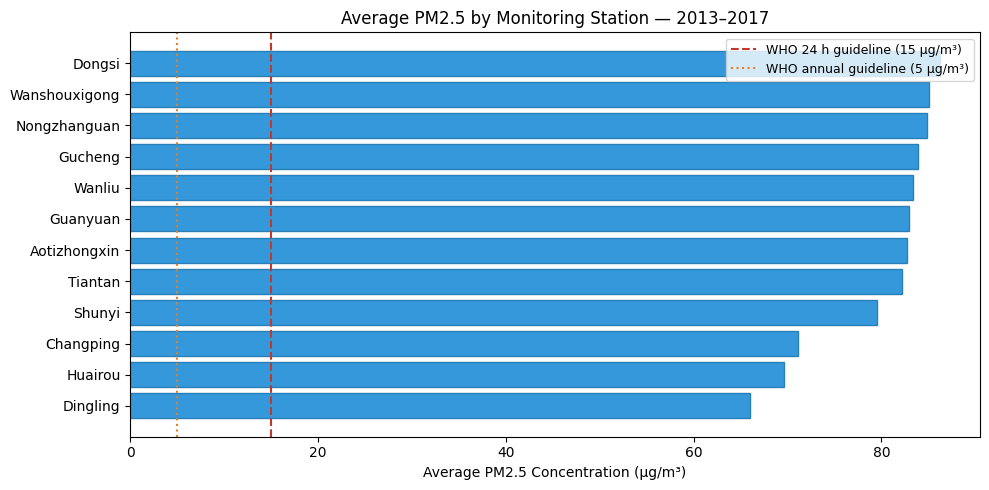

In [12]:
# ── Query 3: Average, maximum, and missing PM2.5 per station ─────────────────
q3 = """
SELECT
    s.station_name,
    ROUND(AVG(r.pm25), 2)                                   AS avg_pm25,
    ROUND(MAX(r.pm25), 2)                                   AS max_pm25,
    COUNT(r.reading_id)                                     AS total_readings,
    SUM(CASE WHEN r.pm25 IS NULL THEN 1 ELSE 0 END)        AS missing_pm25,
    ROUND(
        100.0 * SUM(CASE WHEN r.pm25 IS NULL THEN 1 ELSE 0 END)
              / COUNT(r.reading_id), 1
    )                                                       AS pct_missing
FROM readings r
JOIN stations s ON r.station_id = s.station_id
GROUP BY s.station_name
ORDER BY avg_pm25 DESC;
"""

print('Query 3: Average PM2.5 by station (ranked highest → lowest)')
print('-' * 60)
print(q3)

result_q3 = pd.read_sql_query(text(q3), conn)
display(result_q3)

# Visualisation
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(result_q3['station_name'][::-1], result_q3['avg_pm25'][::-1],
               color='#3498db', edgecolor='#2980b9')
ax.axvline(x=15, color='#c0392b', linestyle='--', linewidth=1.5,
           label='WHO 24 h guideline (15 μg/m³)')
ax.axvline(x=5,  color='#e67e22', linestyle=':',  linewidth=1.5,
           label='WHO annual guideline (5 μg/m³)')
ax.set_xlabel('Average PM2.5 Concentration (μg/m³)')
ax.set_title('Average PM2.5 by Monitoring Station — 2013–2017')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('sql_q3_avg_pm25_by_station.png', dpi=150, bbox_inches='tight')
plt.show()

Query 4: Monthly average PM2.5 trend (all stations)
------------------------------------------------------------

SELECT
    DATE_FORMAT(r.timestamp, '%Y-%m') AS `year_month`,
    ROUND(AVG(r.pm25), 2)           AS avg_pm25,
    ROUND(AVG(r.temp), 2)           AS avg_temp_celsius,
    COUNT(r.reading_id)             AS hourly_obs
FROM readings r
WHERE r.pm25 IS NOT NULL
GROUP BY DATE_FORMAT(r.timestamp, '%Y-%m')
ORDER BY `year_month`;



,year_month,avg_pm25,avg_temp_celsius,hourly_obs
0,2013-03,104.89,6.00,8881
1,2013-04,62.14,12.34,8576
2,2013-05,81.85,21.70,8610
3,2013-06,102.44,23.61,8420
4,2013-07,67.91,27.14,8563
5,2013-08,60.63,26.90,8875
6,2013-09,76.12,20.24,8616
7,2013-10,91.99,12.96,8848
8,2013-11,73.89,5.95,8625
9,2013-12,78.45,0.06,8883


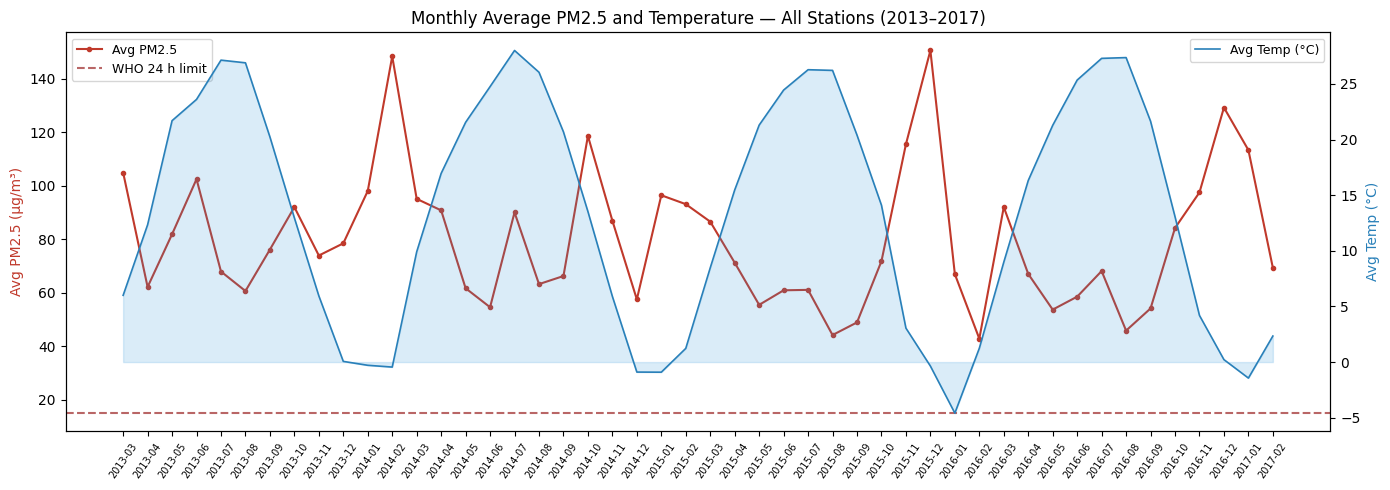

In [13]:
# ── Query 4: Monthly average PM2.5 trend ─────────────────────────────────────
# YEAR_MONTH is a reserved word in MySQL, so the alias is quoted with backticks.
q4 = """
SELECT
    DATE_FORMAT(r.timestamp, '%Y-%m') AS `year_month`,
    ROUND(AVG(r.pm25), 2)           AS avg_pm25,
    ROUND(AVG(r.temp), 2)           AS avg_temp_celsius,
    COUNT(r.reading_id)             AS hourly_obs
FROM readings r
WHERE r.pm25 IS NOT NULL
GROUP BY DATE_FORMAT(r.timestamp, '%Y-%m')
ORDER BY `year_month`;
"""

print('Query 4: Monthly average PM2.5 trend (all stations)')
print('-' * 60)
print(q4)

result_q4 = pd.read_sql_query(text(q4), conn)
display(result_q4)

# Dual-axis chart
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(result_q4['year_month'], result_q4['avg_pm25'],
         color='#c0392b', marker='o', markersize=3, linewidth=1.5, label='Avg PM2.5')
ax1.axhline(y=15, color='darkred', linestyle='--', alpha=0.6, label='WHO 24 h limit')
ax1.set_ylabel('Avg PM2.5 (μg/m³)', color='#c0392b')
ax1.tick_params(axis='x', rotation=55, labelsize=7)
ax1.legend(loc='upper left', fontsize=9)

ax2 = ax1.twinx()
ax2.fill_between(result_q4['year_month'], result_q4['avg_temp_celsius'],
                 alpha=0.18, color='#3498db')
ax2.plot(result_q4['year_month'], result_q4['avg_temp_celsius'],
         color='#2980b9', linewidth=1.2, label='Avg Temp (°C)')
ax2.set_ylabel('Avg Temp (°C)', color='#2980b9')
ax2.legend(loc='upper right', fontsize=9)

plt.title('Monthly Average PM2.5 and Temperature — All Stations (2013–2017)')
plt.tight_layout()
plt.savefig('sql_q4_monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# ── Query 5: WHO PM2.5 guideline exceedance analysis ─────────────────────────
# Joins readings against pollutant_reference so threshold values are not hardcoded.
q5 = """
SELECT
    s.station_name,
    pr.who_24h_limit,
    pr.who_annual_limit,
    COUNT(r.reading_id)                                               AS valid_readings,
    SUM(CASE WHEN r.pm25 > pr.who_24h_limit  THEN 1 ELSE 0 END)     AS hours_above_24h,
    ROUND(
        100.0 * SUM(CASE WHEN r.pm25 > pr.who_24h_limit THEN 1 ELSE 0 END)
              / COUNT(r.reading_id), 1
    )                                                                 AS pct_above_24h,
    ROUND(AVG(r.pm25), 2)                                            AS mean_pm25,
    CASE
        WHEN AVG(r.pm25) > pr.who_annual_limit THEN 'EXCEEDS annual'
        ELSE 'Within annual'
    END                                                               AS annual_status
FROM readings r
JOIN stations s ON r.station_id = s.station_id
CROSS JOIN pollutant_reference pr
WHERE r.pm25 IS NOT NULL
  AND pr.code  = 'PM2.5'
GROUP BY s.station_name, pr.who_24h_limit, pr.who_annual_limit
ORDER BY pct_above_24h DESC;
"""

print('Query 5: WHO PM2.5 guideline exceedance by station')
print('-' * 60)
print(q5)

result_q5 = pd.read_sql_query(text(q5), conn)
display(result_q5)

Query 5: WHO PM2.5 guideline exceedance by station
------------------------------------------------------------

SELECT
    s.station_name,
    pr.who_24h_limit,
    pr.who_annual_limit,
    COUNT(r.reading_id)                                               AS valid_readings,
    SUM(CASE WHEN r.pm25 > pr.who_24h_limit  THEN 1 ELSE 0 END)     AS hours_above_24h,
    ROUND(
        100.0 * SUM(CASE WHEN r.pm25 > pr.who_24h_limit THEN 1 ELSE 0 END)
              / COUNT(r.reading_id), 1
    )                                                                 AS pct_above_24h,
    ROUND(AVG(r.pm25), 2)                                            AS mean_pm25,
    CASE
        WHEN AVG(r.pm25) > pr.who_annual_limit THEN 'EXCEEDS annual'
        ELSE 'Within annual'
    END                                                               AS annual_status
FROM readings r
JOIN stations s ON r.station_id = s.station_id
CROSS JOIN pollutant_reference pr
WHERE r.pm25 IS NOT NULL
  AND pr.code  = 'PM2.5'

,station_name,who_24h_limit,who_annual_limit,valid_readings,hours_above_24h,pct_above_24h,mean_pm25,annual_status
0,Guanyuan,15.0,5.0,34448,28695.0,83.3,82.93,EXCEEDS annual
1,Gucheng,15.0,5.0,34418,28573.0,83.0,83.85,EXCEEDS annual
2,Wanliu,15.0,5.0,34682,28691.0,82.7,83.37,EXCEEDS annual
3,Aotizhongxin,15.0,5.0,34139,28022.0,82.1,82.77,EXCEEDS annual
4,Tiantan,15.0,5.0,34387,28149.0,81.9,82.16,EXCEEDS annual
5,Wanshouxigong,15.0,5.0,34368,28138.0,81.9,85.02,EXCEEDS annual
6,Dongsi,15.0,5.0,34314,28017.0,81.6,86.19,EXCEEDS annual
7,Nongzhanguan,15.0,5.0,34436,28078.0,81.5,84.84,EXCEEDS annual
8,Shunyi,15.0,5.0,34151,27134.0,79.5,79.49,EXCEEDS annual
9,Changping,15.0,5.0,34290,26873.0,78.4,71.10,EXCEEDS annual


---
## Section 4: MongoDB Database Design

### Collection: `air_quality_readings`

Each document represents **one hourly observation at one station**.
Pollutant measurements and weather readings are stored in **nested sub-documents**
to reflect their natural grouping and to allow selective field projection in queries.

#### Document Schema

```json
{
  "_id": ObjectId("..."),
  "station":   "Dongsi",
  "timestamp": ISODate("2013-03-01T00:00:00Z"),
  "year": 2013, "month": 3, "day": 1, "hour": 0,
  "pollutants": {
    "pm25": 9.0,  "pm10": 9.0,  "so2": 3.0,
    "no2":  17.0, "co":  300.0, "o3":  89.0
  },
  "weather": {
    "temp":           -0.5,
    "pressure":       1024.5,
    "dew_point":      -21.4,
    "rainfall":       0.0,
    "wind_direction": "NNW",
    "wind_speed":     5.7
  }
}
```

#### Indexes (created on Atlas)

| Index | Type | Supports |
|-------|------|----------|
| `station` + `timestamp` | Compound | Latest-record and date-range queries |
| `timestamp` | Single field | Global time-range scans |
| `pollutants.pm25` | Single field | Threshold / alert queries |

#### SQL vs MongoDB — Design Comparison

| Aspect | MySQL (`readings`) | MongoDB (`air_quality_readings`) |
|--------|-------------------|----------------------------------|
| Data model | Flat row, 14 columns | Nested sub-documents |
| Station reference | FK to `stations` table | Embedded string field |
| Schema enforcement | DDL constraints | Application-level / JSON Schema validation |
| Query style | JOIN-based SQL | `find()` + aggregation pipeline |
| Best suited for | Structured analytics, multi-table JOINs | Flexible retrieval, document-oriented access |

In [15]:
# ── Connect to MongoDB Atlas ──────────────────────────────────────────────────
client     = MongoClient(os.environ['MONGO_URI'], serverSelectionTimeoutMS=10000)
db_mongo   = client[os.getenv('MONGO_DB_NAME', 'beijing_air_quality')]
collection = db_mongo[os.getenv('MONGO_COLLECTION', 'air_quality_readings')]

client.admin.command('ping')
print('MongoDB connection established.')
print(f'  Engine    : MongoDB {client.server_info()["version"]} (Atlas)')
print(f'  Database  : {db_mongo.name}')
print(f'  Collection: {collection.name}')

MongoDB connection established.
  Engine    : MongoDB 8.0.34 (Atlas)
  Database  : beijing_air_quality
  Collection: air_quality_readings


In [16]:
# ── Verify the collection against the source CSVs ────────────────────────────
# The 420 768 documents were inserted once by database/load_data.py using the
# design above. Here we check the count, the indexes, and that one CSV row maps
# to exactly the stored document.

def _safe(v):
    """Return None instead of NaN so documents serialise correctly."""
    if isinstance(v, float) and math.isnan(v):
        return None
    return v

def to_document(r):
    """One CSV row → one nested air_quality_readings document."""
    return {
        'station':   r['station'],
        'timestamp': r['timestamp'].to_pydatetime(),
        'year':  int(r['year']), 'month': int(r['month']),
        'day':   int(r['day']),  'hour':  int(r['hour']),
        'pollutants': {
            'pm25': _safe(r['PM2.5']), 'pm10': _safe(r['PM10']), 'so2': _safe(r['SO2']),
            'no2':  _safe(r['NO2']),   'co':   _safe(r['CO']),   'o3':  _safe(r['O3']),
        },
        'weather': {
            'temp':           _safe(r['TEMP']),
            'pressure':       _safe(r['PRES']),
            'dew_point':      _safe(r['DEWP']),
            'rainfall':       _safe(r['RAIN']),
            'wind_direction': r['wd'] if isinstance(r['wd'], str) else None,
            'wind_speed':     _safe(r['WSPM']),
        },
    }

doc_count = collection.count_documents({})
print(f'Rows in CSV files       : {len(df_raw):,}')
print(f'Documents in collection : {doc_count:,}')
assert doc_count == len(df_raw), 'Document count in MongoDB does not match the CSVs'

print('\nIndexes:')
for name, spec in collection.index_information().items():
    print(f'  {name:<18} {spec["key"]}{"  (unique)" if spec.get("unique") else ""}')

# Spot-check: rebuild the document for one CSV row and compare with Atlas
row      = df_raw[(df_raw['station'] == 'Dongsi')].sort_values('timestamp').iloc[0]
expected = to_document(row)
stored   = collection.find_one({'station': row['station'], 'timestamp': expected['timestamp']}, {'_id': 0})
print('\nSpot-check (Dongsi, first hour): stored document matches CSV row →', stored == expected)

Rows in CSV files       : 420,768
Documents in collection : 420,768

Indexes:
  _id_               [('_id', 1)]
  station_timestamp  [('station', 1), ('timestamp', 1)]  (unique)
  timestamp          [('timestamp', -1)]
  pm25               [('pollutants.pm25', 1)]



Spot-check (Dongsi, first hour): stored document matches CSV row → True


In [17]:
# Show three sample documents from the Dongsi station
print('Sample documents from air_quality_readings (Dongsi station):\n')
samples = list(collection.find({'station': 'Dongsi'}).limit(3))
for doc in samples:
    doc.pop('_id', None)          # remove ObjectId for clean display
    print(json.dumps(doc, indent=2, default=str))
    print('─' * 45)

Sample documents from air_quality_readings (Dongsi station):

{
  "station": "Dongsi",
  "timestamp": "2013-03-01 00:00:00",
  "year": 2013,
  "month": 3,
  "day": 1,
  "hour": 0,
  "pollutants": {
    "pm25": 9.0,
    "pm10": 9.0,
    "so2": 3.0,
    "no2": 17.0,
    "co": 300.0,
    "o3": 89.0
  },
  "weather": {
    "temp": -0.5,
    "pressure": 1024.5,
    "dew_point": -21.4,
    "rainfall": 0.0,
    "wind_direction": "NNW",
    "wind_speed": 5.7
  }
}
─────────────────────────────────────────────
{
  "station": "Dongsi",
  "timestamp": "2013-03-01 01:00:00",
  "year": 2013,
  "month": 3,
  "day": 1,
  "hour": 1,
  "pollutants": {
    "pm25": 4.0,
    "pm10": 4.0,
    "so2": 3.0,
    "no2": 16.0,
    "co": 300.0,
    "o3": 88.0
  },
  "weather": {
    "temp": -0.7,
    "pressure": 1025.1,
    "dew_point": -22.1,
    "rainfall": 0.0,
    "wind_direction": "NW",
    "wind_speed": 3.9
  }
}
─────────────────────────────────────────────
{
  "station": "Dongsi",
  "timestamp": "2013-03-

---
## MongoDB Queries

| # | Query type | Description |
|---|-----------|-------------|
| MQ-1 | `find().sort().limit()` | Latest reading for a specific station |
| MQ-2 | `find()` with `$gte`/`$lte` | All documents within a date range |
| MQ-3 | Aggregation pipeline (`$group`) | Average PM2.5 per station |
| MQ-4 | Aggregation pipeline (`$group` + `$cond`) | Hazardous-reading count and percentage per station |

In [18]:
# ── MQ-1: Latest reading for Dongsi station ───────────────────────────────────
print('MongoDB Query 1: Latest reading for Dongsi station')
print('-' * 60)
print("""
db.air_quality_readings.find(
    { "station": "Dongsi" },
    { "_id": 0, "station": 1, "timestamp": 1,
      "pollutants": 1, "weather.temp": 1, "weather.wind_direction": 1 }
).sort({ "timestamp": -1 }).limit(1)
""")

result_mq1 = list(
    collection.find(
        {'station': 'Dongsi'},
        {'_id': 0, 'station': 1, 'timestamp': 1,
         'pollutants': 1, 'weather': 1}
    ).sort('timestamp', -1).limit(1)
)

print('Result:')
for doc in result_mq1:
    print(json.dumps(doc, indent=2, default=str))

MongoDB Query 1: Latest reading for Dongsi station
------------------------------------------------------------

db.air_quality_readings.find(
    { "station": "Dongsi" },
    { "_id": 0, "station": 1, "timestamp": 1,
      "pollutants": 1, "weather.temp": 1, "weather.wind_direction": 1 }
).sort({ "timestamp": -1 }).limit(1)



Result:
{
  "station": "Dongsi",
  "timestamp": "2017-02-28 23:00:00",
  "pollutants": {
    "pm25": 30.0,
    "pm10": 71.0,
    "so2": 11.0,
    "no2": 87.0,
    "co": 1200.0,
    "o3": 4.0
  },
  "weather": {
    "temp": 8.6,
    "pressure": 1014.1,
    "dew_point": -15.9,
    "rainfall": 0.0,
    "wind_direction": "NNE",
    "wind_speed": 1.3
  }
}


In [19]:
# ── MQ-2: Date-range query — Dongsi, 1–7 January 2016 ────────────────────────
start_dt = datetime(2016, 1, 1,  0, 0, 0)
end_dt   = datetime(2016, 1, 7, 23, 0, 0)

print('MongoDB Query 2: Date-range — Dongsi, 1–7 January 2016')
print('-' * 60)
print(f"""
db.air_quality_readings.find(
    {{
        "station": "Dongsi",
        "timestamp": {{
            "$gte": ISODate("{start_dt.isoformat()}"),
            "$lte": ISODate("{end_dt.isoformat()}")
        }}
    }},
    {{ "_id": 0, "station": 1, "timestamp": 1,
      "pollutants.pm25": 1, "pollutants.pm10": 1,
      "weather.temp": 1, "weather.wind_direction": 1 }}
).sort({{ "timestamp": 1 }})
""")

cur_mq2 = collection.find(
    {
        'station':   'Dongsi',
        'timestamp': {'$gte': start_dt, '$lte': end_dt}
    },
    {'_id': 0, 'station': 1, 'timestamp': 1,
     'pollutants': 1, 'weather': 1}
).sort('timestamp', 1)

result_mq2 = list(cur_mq2)
print(f'Total documents returned: {len(result_mq2)}')

rows = [
    {
        'station':        d['station'],
        'timestamp':      d['timestamp'],
        'pm25':           d['pollutants'].get('pm25'),
        'pm10':           d['pollutants'].get('pm10'),
        'temp':           d['weather'].get('temp'),
        'wind_direction': d['weather'].get('wind_direction'),
    }
    for d in result_mq2
]
mq2_df = pd.DataFrame(rows)
print('\nFirst 10 rows:')
display(mq2_df.head(10))

MongoDB Query 2: Date-range — Dongsi, 1–7 January 2016
------------------------------------------------------------

db.air_quality_readings.find(
    {
        "station": "Dongsi",
        "timestamp": {
            "$gte": ISODate("2016-01-01T00:00:00"),
            "$lte": ISODate("2016-01-07T23:00:00")
        }
    },
    { "_id": 0, "station": 1, "timestamp": 1,
      "pollutants.pm25": 1, "pollutants.pm10": 1,
      "weather.temp": 1, "weather.wind_direction": 1 }
).sort({ "timestamp": 1 })



Total documents returned: 168

First 10 rows:


,station,timestamp,pm25,pm10,temp,wind_direction
0,Dongsi,2016-01-01 00:00:00,200.0,209.0,-2.5,NNE
1,Dongsi,2016-01-01 01:00:00,193.0,203.0,-3.5,NE
2,Dongsi,2016-01-01 02:00:00,219.0,237.0,-4.7,ENE
3,Dongsi,2016-01-01 03:00:00,187.0,196.0,-3.6,ENE
4,Dongsi,2016-01-01 04:00:00,160.0,160.0,-5.1,E
5,Dongsi,2016-01-01 05:00:00,116.0,116.0,-5.7,ENE
6,Dongsi,2016-01-01 06:00:00,111.0,117.0,-6.3,ENE
7,Dongsi,2016-01-01 07:00:00,124.0,139.0,-6.8,E
8,Dongsi,2016-01-01 08:00:00,106.0,118.0,-6.8,ENE
9,Dongsi,2016-01-01 09:00:00,93.0,93.0,-3.6,E


In [20]:
# ── MQ-3: Average PM2.5 per station (aggregation pipeline) ───────────────────
print('MongoDB Query 3: Average PM2.5 per station')
print('-' * 60)
print("""
db.air_quality_readings.aggregate([
    { "$match": { "pollutants.pm25": { "$ne": null } } },
    { "$group": {
        "_id":       "$station",
        "avg_pm25":  { "$avg": "$pollutants.pm25" },
        "max_pm25":  { "$max": "$pollutants.pm25" },
        "doc_count": { "$sum": 1 }
    }},
    { "$sort": { "avg_pm25": -1 } }
])
""")

pipeline_mq3 = [
    {'$match': {'pollutants.pm25': {'$ne': None}}},
    {'$group': {
        '_id':       '$station',
        'avg_pm25':  {'$avg': '$pollutants.pm25'},
        'max_pm25':  {'$max': '$pollutants.pm25'},
        'doc_count': {'$sum': 1},
    }},
    {'$sort': {'avg_pm25': -1}},
]

result_mq3 = list(collection.aggregate(pipeline_mq3))

mq3_df = pd.DataFrame([
    {
        'station':   r['_id'],
        'avg_pm25':  round(r['avg_pm25'], 2),
        'max_pm25':  round(r['max_pm25'], 2),
        'doc_count': r['doc_count'],
    }
    for r in result_mq3
])

print('Result:')
display(mq3_df)

MongoDB Query 3: Average PM2.5 per station
------------------------------------------------------------

db.air_quality_readings.aggregate([
    { "$match": { "pollutants.pm25": { "$ne": null } } },
    { "$group": {
        "_id":       "$station",
        "avg_pm25":  { "$avg": "$pollutants.pm25" },
        "max_pm25":  { "$max": "$pollutants.pm25" },
        "doc_count": { "$sum": 1 }
    }},
    { "$sort": { "avg_pm25": -1 } }
])



Result:


,station,avg_pm25,max_pm25,doc_count
0,Dongsi,86.19,737.0,34314
1,Wanshouxigong,85.02,999.0,34368
2,Nongzhanguan,84.84,844.0,34436
3,Gucheng,83.85,770.0,34418
4,Wanliu,83.37,957.0,34682
5,Guanyuan,82.93,680.0,34448
6,Aotizhongxin,82.77,898.0,34139
7,Tiantan,82.16,821.0,34387
8,Shunyi,79.49,941.0,34151
9,Changping,71.10,882.0,34290


MongoDB Query 4: Hazardous PM2.5 readings (PM2.5 > 150 μg/m³) per station
------------------------------------------------------------

db.air_quality_readings.aggregate([
    { "$match": { "pollutants.pm25": { "$ne": null } } },
    { "$group": {
        "_id":       "$station",
        "total":     { "$sum": 1 },
        "hazardous": {
            "$sum": { "$cond": [ { "$gt": ["$pollutants.pm25", 150] }, 1, 0 ] }
        }
    }},
    { "$addFields": {
        "pct_hazardous": {
            "$round": [
                { "$multiply": [ { "$divide": ["$hazardous", "$total"] }, 100 ] }, 1
            ]
        }
    }},
    { "$sort": { "pct_hazardous": -1 } }
])



Result:


,station,total_readings,hazardous_readings,pct_hazardous
0,Dongsi,34314,5940,17.3
1,Nongzhanguan,34436,5802,16.8
2,Wanshouxigong,34368,5719,16.6
3,Wanliu,34682,5656,16.3
4,Aotizhongxin,34139,5526,16.2
5,Gucheng,34418,5460,15.9
6,Tiantan,34387,5461,15.9
7,Guanyuan,34448,5431,15.8
8,Shunyi,34151,5227,15.3
9,Changping,34290,4374,12.8


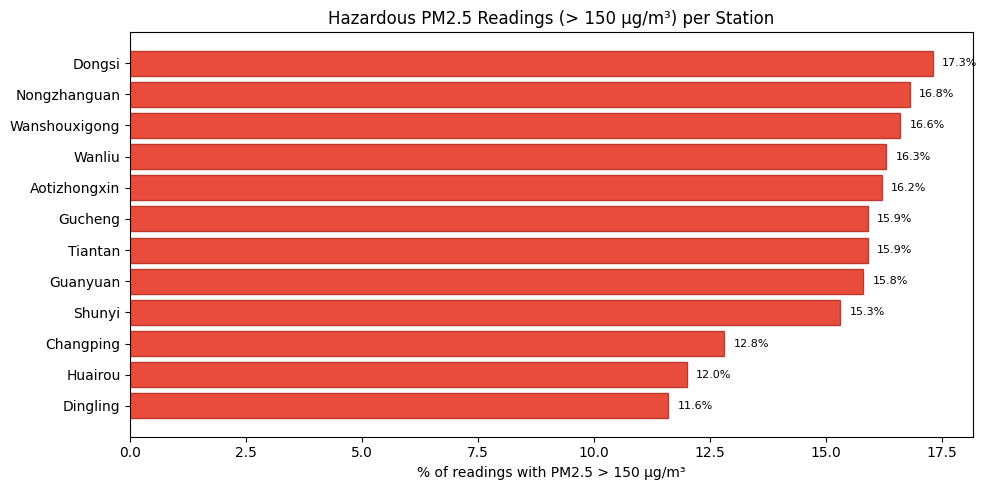

In [21]:
# ── MQ-4: Hazardous PM2.5 readings per station (PM2.5 > 150 μg/m³) ───────────
print('MongoDB Query 4: Hazardous PM2.5 readings (PM2.5 > 150 μg/m³) per station')
print('-' * 60)
print("""
db.air_quality_readings.aggregate([
    { "$match": { "pollutants.pm25": { "$ne": null } } },
    { "$group": {
        "_id":       "$station",
        "total":     { "$sum": 1 },
        "hazardous": {
            "$sum": { "$cond": [ { "$gt": ["$pollutants.pm25", 150] }, 1, 0 ] }
        }
    }},
    { "$addFields": {
        "pct_hazardous": {
            "$round": [
                { "$multiply": [ { "$divide": ["$hazardous", "$total"] }, 100 ] }, 1
            ]
        }
    }},
    { "$sort": { "pct_hazardous": -1 } }
])
""")

pipeline_mq4 = [
    {'$match': {'pollutants.pm25': {'$ne': None}}},
    {'$group': {
        '_id':       '$station',
        'total':     {'$sum': 1},
        'hazardous': {'$sum': {'$cond': [{'$gt': ['$pollutants.pm25', 150]}, 1, 0]}},
    }},
    {'$addFields': {
        'pct_hazardous': {
            '$round': [{'$multiply': [{'$divide': ['$hazardous', '$total']}, 100]}, 1]
        }
    }},
    {'$sort': {'pct_hazardous': -1}},
]

mq4_df = pd.DataFrame([
    {
        'station':            r['_id'],
        'total_readings':     r['total'],
        'hazardous_readings': r['hazardous'],
        'pct_hazardous':      r['pct_hazardous'],
    }
    for r in collection.aggregate(pipeline_mq4)
])

print('Result:')
display(mq4_df)

# Visualisation
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(mq4_df['station'][::-1], mq4_df['pct_hazardous'][::-1],
               color='#e74c3c', edgecolor='#c0392b')
ax.set_xlabel('% of readings with PM2.5 > 150 μg/m³')
ax.set_title('Hazardous PM2.5 Readings (> 150 μg/m³) per Station')
for bar, pct in zip(bars, mq4_df['pct_hazardous'][::-1]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
            f'{pct}%', va='center', fontsize=8)
plt.tight_layout()
plt.savefig('mongo_q4_hazardous_pm25.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Summary

### Databases Implemented

| Database | Engine | Tables / Collections | Total records |
|----------|--------|---------------------|---------------|
| Relational | MySQL 8.4 (Aiven) | `stations`, `readings`, `pollutant_reference` | 420 768 readings + 12 stations + 6 pollutants |
| Document | MongoDB (Atlas) | `air_quality_readings` | 420 768 documents |

### Queries Executed

| ID | Database | Type | Description |
|----|----------|------|-------------|
| Q1 | MySQL | SELECT + subquery | Latest reading per station |
| Q2 | MySQL | SELECT + BETWEEN | Date-range filter (Dongsi, Jan 1–7 2016) |
| Q3 | MySQL | GROUP BY + aggregate | Average/max PM2.5 ranked by station |
| Q4 | MySQL | GROUP BY + date function | Monthly PM2.5 and temperature trend |
| Q5 | MySQL | CROSS JOIN + CASE | WHO 2021 guideline exceedance analysis |
| MQ-1 | MongoDB | `find().sort().limit()` | Latest document for a station |
| MQ-2 | MongoDB | `find()` + `$gte`/`$lte` | Date-range document retrieval |
| MQ-3 | MongoDB | Aggregation `$group` | Average PM2.5 per station |
| MQ-4 | MongoDB | Aggregation `$group` + `$cond` | Hazardous-reading % per station |

### Key Findings from Queries

- **Q3/MQ-3**: Dongsi and Wanshouxigong consistently rank as the most polluted stations; Dingling and Huairou (suburban/rural) record the lowest average PM2.5.
- **Q4**: Winter months (December–February) show markedly higher PM2.5 than summer, consistent with coal heating and lower wind speeds during temperature inversions.
- **Q5**: Every station exceeds the WHO 24-hour PM2.5 guideline (15 μg/m³) in at least 72% of hourly observations (Dingling 72.4% to Guanyuan 83.3%), and every station mean exceeds the WHO annual guideline (5 μg/m³) by more than thirteenfold.
- **MQ-4**: Dongsi has the highest share of truly hazardous hours (PM2.5 > 150 μg/m³, 17.3%), followed by Nongzhanguan and Wanshouxigong; Dingling has the lowest (11.6%).